# EMQA_L6_capture_rates

**Capture rate of Romanian solar and onshore wind by calendar year, 2019 to 2026-10-31 (2026 = Jan-Oct): generation-weighted mean day-ahead price divided by the baseload price, in %; hourly prices to Sep 2025, 15-min from Oct 2025. Prints the solar capture rates of 2019, the last full year and the current year, the range of the wind capture rate and the like-for-like change in solar output.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_capture_rates/EMQA_L6_capture_rates.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Capture price CP = sum_t p_t g_t dt_t / sum_t g_t dt_t; baseload B = sum_t p_t dt_t / sum_t dt_t; capture rate CR = CP / B (years with at least 90% of the generation intervals reported).

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert('UTC').floor('1h').tz_convert(TZ)


def load_gen(c):
    """Generation and load of country c (ro, bg, hu), MW, native resolution, CET/CEST index."""
    g = pd.read_csv(DATA + f'generation_{c}_mw_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
    g.index = g.index.tz_convert(TZ)
    return g


def on_price_grid(g):
    """Generation columns on the price grid: hourly mean for hourly prices; 15-min value for 15-min prices
    (the hourly value is repeated when the source is hourly, as for Bulgaria)."""
    gg = g.drop(columns=['mtu_minutes']).copy()
    out = gg.resample('1h').mean().reindex(hfloor(PX.index)).set_axis(PX.index)
    q15 = PX['mtu_minutes'] == 15
    if (g['mtu_minutes'] == 15).loc[g.index >= MTU15].all():
        out.loc[q15] = gg.resample('15min').mean().reindex(PX.index[q15]).values
    return out


GN = {c.upper(): load_gen(c) for c in ('ro',)}
GR = {z: on_price_grid(GN[z]) for z in GN}
print({z: (str(g.index.min())[:10], str(g.index.max())[:10]) for z, g in GN.items()})

{'RO': ('2018-12-30', '2026-11-04')}


In [6]:
def capture(zone, tech, mask):
    """Capture price = generation-weighted mean price; baseload = duration-weighted mean price (EUR/MWh)."""
    p, w = PX[zone], GR[zone][tech] * PX['dur']
    m = mask & p.notna() & w.notna()
    base_m = mask & p.notna()
    cp = float((p[m] * w[m]).sum() / w[m].sum())
    base = float((p[base_m] * PX['dur'][base_m]).sum() / PX['dur'][base_m].sum())
    return cp, base, float(w[m].sum())


def capture_years(zones, techs):
    """Capture rate by calendar year (years with at least 90% of the generation intervals reported)."""
    out = {}
    for z in zones:
        for tech in techs:
            for y in YEARS:
                m = pd.Series(LOC_YEAR == y, index=PX.index)
                if GR[z][tech][m].notna().sum() < 0.9 * m.sum():
                    continue
                cp, base, e = capture(z, tech, m)
                out[(z, tech, y)] = {'cp': cp, 'base': base, 'crp': fl(cp / base * 100, 1)}
    return out

In [7]:
CAPT = capture_years(['RO'], ['solar', 'wind_onshore'])
ro, dur = GR['RO'], PX['dur']
lfl = {}
for y in (Y - 1, Y):
    m = (LOC_YEAR == y) & (PX.index.month <= END.month)
    lfl[y] = fl((ro['solar'][m] * dur[m]).sum() / 1e6, 2)
wind = [CAPT[('RO', 'wind_onshore', y)]['crp'] for y in YEARS if ('RO', 'wind_onshore', y) in CAPT]
show_numbers({'capt.RO.solar.2019.crp': CAPT[('RO', 'solar', 2019)]['crp'],
              f'capt.RO.solar.{Y - 1}.crp': CAPT[('RO', 'solar', Y - 1)]['crp'],
              f'capt.RO.solar.{Y}.crp': CAPT[('RO', 'solar', Y)]['crp'],
              'capt.RO.wind_min': min(wind), 'capt.RO.wind_max': max(wind),
              'twh_lfl.solar_chg': fl((lfl[Y] / lfl[Y - 1] - 1) * 100, 1)})

capt.RO.solar.2019.crp             104.5
capt.RO.solar.2025.crp             59.4
capt.RO.solar.2026.crp             61.9
capt.RO.wind_min                   88.4
capt.RO.wind_max                   103.0
twh_lfl.solar_chg                  70.8


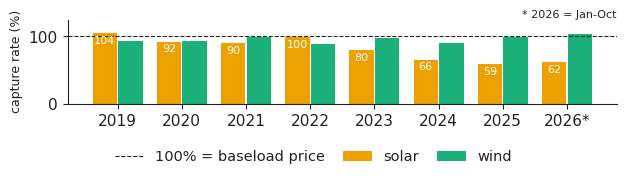

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 1.85))
xs = np.arange(len(YEARS))
sol = [CAPT[('RO', 'solar', y)]['crp'] for y in YEARS]
ax.bar(xs - 0.2, sol, width=0.38, color=PAL['BG'], label='solar')
ax.bar(xs + 0.2, [CAPT[('RO', 'wind_onshore', y)]['crp'] for y in YEARS], width=0.38, color=PAL['HU'], label='wind')
ax.axhline(100, color=INK, lw=0.8, ls='--', label='100% = baseload price')
for i, v in enumerate(sol):
    ax.text(i - 0.2, v - 4, f'{v:.0f}', ha='center', va='top', fontsize=8, color='white')
ax.set_xticks(xs)
ax.set_xticklabels([str(y) + ('*' if y == Y else '') for y in YEARS])
ax.set_ylim(0, 125)
ax.set_ylabel('capture rate (%)', fontsize=9)
ax.text(1.0, 1.02, YTD, transform=ax.transAxes, fontsize=8, ha='right')
legend_bottom(fig, ncol=3)
fig.canvas.draw()
legend_h = max([lg.get_window_extent().height for lg in fig.legends] or [0.0]) / fig.bbox.height
fig.tight_layout(rect=(0, legend_h + 0.035, 1, 1))
plt.savefig('capture_rates.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()